# Project MVP: ResNet-18 for Prior Myocardial Infarction Detection
This notebook implements a 1D ResNet-18 architecture for detecting prior Myocardial Infarction using Lead I ECG signals, replicating the methodology of the Obermeyer et al. 2026 paper using the PTB-XL dataset.

### Pipeline Stages:
1. Data loading and preprocessing (Lead I extraction).
2. Model architecture (1D ResNet-18).
3. Training & Evaluation Engine.
4. Hyperparameter Optimization (Optuna).
5. Final training with best parameters.
6. **Cross-Dataset Evaluation (Shaoxing)**.
7. **Fine-tuning on Shaoxing Data**.
8. Performance visualization.

In [1]:
import os
import pandas as pd
import numpy as np
import wfdb
import ast
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
from sklearn.metrics import roc_auc_score
import optuna
from scipy import signal as scipy_signal
import duckdb
from datetime import datetime

# Set device
device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
print(f"Using device: {device}")

# Checkpoint directory
os.makedirs("checkpoints", exist_ok=True)

# Initialize DuckDB for experiment tracking
db = duckdb.connect("experiment_results.duckdb")
db.execute("""
    CREATE TABLE IF NOT EXISTS runs (
        run_id VARCHAR,
        timestamp TIMESTAMP,
        stage VARCHAR,
        dataset VARCHAR,
        epoch INTEGER,
        train_loss DOUBLE,
        train_auc DOUBLE,
        val_loss DOUBLE,
        val_auc DOUBLE,
        notes VARCHAR
    )
""")
db.execute("""
    CREATE TABLE IF NOT EXISTS model_exports (
        run_id VARCHAR,
        timestamp TIMESTAMP,
        format VARCHAR,
        path VARCHAR,
        size_mb DOUBLE,
        source_stage VARCHAR
    )
""")
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
print(f"Run ID: {RUN_ID}")


Using device: mps
Run ID: 20260402_173412


## 1. Data Loading & Preprocessing (PTB-XL)

In [2]:
ptb_path = '../data/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/'

def load_ptbxl_data(path):
    df = pd.read_csv(os.path.join(path, 'ptbxl_database.csv'), index_col=0)
    df.scp_codes = df.scp_codes.apply(lambda x: ast.literal_eval(x))
    return df

def aggregate_diagnostic(y_dic, agg_df):
    tmp = []
    for key in y_dic.keys():
        if key in agg_df.index: tmp.append(agg_df.loc[key].diagnostic_class)
    return list(set(tmp))

agg_df = pd.read_csv(os.path.join(ptb_path, 'scp_statements.csv'), index_col=0)
agg_df = agg_df[agg_df.diagnostic == 1]

df = load_ptbxl_data(ptb_path)
df['diagnostic_class'] = df.scp_codes.apply(aggregate_diagnostic, agg_df=agg_df)
df['MI'] = df.diagnostic_class.apply(lambda x: 1 if 'MI' in x else 0)

print(f"Total PTB-XL samples: {len(df)} | MI prevalence: {df.MI.mean()*100:.2f}%")

Total PTB-XL samples: 21799 | MI prevalence: 25.09%


In [3]:
class PTBXLDataset(Dataset):
    def __init__(self, df, base_path, lead_idx=0):
        self.df = df
        self.base_path = base_path
        self.lead_idx = lead_idx
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        filename = os.path.join(self.base_path, self.df.iloc[idx].filename_lr)
        signal, meta = wfdb.rdsamp(filename)
        lead_signal = signal[:, self.lead_idx]
        lead_signal = (lead_signal - np.mean(lead_signal)) / (np.std(lead_signal) + 1e-8)
        label = self.df.iloc[idx].MI
        return torch.tensor(lead_signal, dtype=torch.float32).unsqueeze(0), torch.tensor(label, dtype=torch.float32)

train_df = df[df.strat_fold < 9]
val_df = df[df.strat_fold == 9]
test_df = df[df.strat_fold == 10]

print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

Train: 17418, Val: 2183, Test: 2198


## 2. Shaoxing Dataset Loader (Cross-Validation Dataset)

In [4]:
shaoxing_path = '../data/a-large-scale-12-lead-electrocardiogram-database-for-arrhythmia-study-1.0.0/'
MI_CODE = '164865005' # Snomed code for MI

class ShaoxingDataset(Dataset):
    def __init__(self, base_path, lead_idx=0, limit=None):
        self.base_path = base_path
        self.lead_idx = lead_idx
        
        # Load all record paths from recursive discovery or 'RECORDS' file
        self.records = []
        records_file = os.path.join(base_path, 'RECORDS')
        with open(records_file, 'r') as f:
            subfolders = [line.strip() for line in f if line.strip()]
        
        print(f"Scanning Shaoxing subfolders...")
        for sub in subfolders:
            if limit and len(self.records) >= limit: break
            sub_path = os.path.join(base_path, sub)
            if os.path.exists(sub_path):
                files = [f.replace('.hea', '') for f in os.listdir(sub_path) if f.endswith('.hea')]
                for f in files:
                    self.records.append(os.path.join(sub, f))
                    if limit and len(self.records) >= limit: break
        
        if limit: self.records = self.records[:limit]
        print(f"Found {len(self.records)} Shaoxing records.")

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec_path = os.path.join(self.base_path, self.records[idx])
        try:
            # Use wfdb to load .mat and metadata
            signal, meta = wfdb.rdsamp(rec_path)
            
            # Shaoxing is 500Hz, PTB-XL model is 100Hz -> Downsample by 5
            lead_signal = signal[::5, self.lead_idx]
            
            # Standardize
            lead_signal = (lead_signal - np.mean(lead_signal)) / (np.std(lead_signal) + 1e-8)
            
            # Extract labels from metadata
            dx_list = []
            for comment in meta['comments']:
                if 'Dx:' in comment:
                    dx_str = comment.split('Dx:')[1].strip()
                    dx_list = [c.strip() for c in dx_str.split(',')]
                    break
            
            label = 1 if MI_CODE in dx_list else 0
            return torch.tensor(lead_signal, dtype=torch.float32).unsqueeze(0), torch.tensor(label, dtype=torch.float32)
        except Exception as e:
            # Return a zero dummy signal for malformed records to avoid pipeline crash
            dummy = np.zeros(1000)
            return torch.tensor(dummy, dtype=torch.float32).unsqueeze(0), torch.tensor(0, dtype=torch.float32)

# Increase limit for better label prevalence in small subset
shaoxing_dataset = ShaoxingDataset(shaoxing_path, limit=5000)
print(f"Shaoxing sample label check: {shaoxing_dataset[0][1].item()}")

Scanning Shaoxing subfolders...
Found 5000 Shaoxing records.
Shaoxing sample label check: 0.0


## 3. Model Architecture: 1D ResNet-18

In [5]:
def conv3x1(in_planes, out_planes, stride=1):
    return nn.Conv1d(in_planes, out_planes, kernel_size=3, stride=stride, padding=1, bias=False)

class BasicBlock1D(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super(BasicBlock1D, self).__init__()
        self.conv1 = conv3x1(inplanes, planes, stride)
        self.bn1 = nn.BatchNorm1d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x1(planes, planes)
        self.bn2 = nn.BatchNorm1d(planes)
        self.downsample = downsample

    def forward(self, x):
        residual = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        if self.downsample is not None: residual = self.downsample(x)
        out += residual
        out = self.relu(out)
        return out

class ResNet1D(nn.Module):
    def __init__(self, block, layers, num_classes=1):
        self.inplanes = 64
        super(ResNet1D, self).__init__()
        self.conv1 = nn.Conv1d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2)
        self.avgpool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv1d(self.inplanes, planes * block.expansion, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(planes * block.expansion),
            )
        layers = [block(self.inplanes, planes, stride, downsample)]
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks): layers.append(block(self.inplanes, planes))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        return self.fc(x.view(x.size(0), -1))

def resnet18_1d(): return ResNet1D(BasicBlock1D, [2, 2, 2, 2])

## 4. Training & Evaluation Engine

In [6]:
def evaluate(loader, model, criterion, device):
    model.eval()
    all_losses, all_preds, all_targets = [], [], []
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs).squeeze()
            if outputs.dim() == 0: outputs = outputs.unsqueeze(0)
            loss = criterion(outputs, targets)
            all_losses.append(loss.item())
            all_preds.extend(torch.sigmoid(outputs).cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
    
    if len(set(all_targets)) < 2:
        return np.mean(all_losses), 0.5
    return np.mean(all_losses), roc_auc_score(all_targets, all_preds)

def train_epoch(loader, model, criterion, optimizer, device, limit=None):
    model.train()
    losses, preds, targets = [], [], []
    for i, (inputs, labels) in enumerate(loader):
        if limit and i >= limit: break
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs).squeeze()
        if outputs.dim() == 0: outputs = outputs.unsqueeze(0)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        preds.extend(torch.sigmoid(outputs).detach().cpu().numpy())
        targets.extend(labels.cpu().numpy())
    
    if len(set(targets)) < 2:
        return np.mean(losses), 0.5
    return np.mean(losses), roc_auc_score(targets, preds)

## 5. Hyperparameter Optimization: Optuna (on PTB-XL)

In [7]:
def objective(trial):
    lr = trial.suggest_float("lr", 1e-5, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])
    
    train_loader = DataLoader(PTBXLDataset(train_df, ptb_path), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(PTBXLDataset(val_df, ptb_path), batch_size=batch_size)
    
    model = resnet18_1d().to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()
    
    train_epoch(train_loader, model, criterion, optimizer, device, limit=30)
    val_loss, val_auc = evaluate(val_loader, model, criterion, device)
    
    return val_auc

print("Starting Optuna Study...")
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=3)

print(f"Best trial AUC: {study.best_trial.value:.4f}")
print(f"Best params: {study.best_params}")

[I 2026-04-02 17:34:13,525] A new study created in memory with name: no-name-e7b95537-aba6-458d-bfb5-dd0e83d1a392


Starting Optuna Study...


[I 2026-04-02 17:34:27,303] Trial 0 finished with value: 0.6584826762246117 and parameters: {'lr': 0.003025171930738083, 'batch_size': 64}. Best is trial 0 with value: 0.6584826762246117.
[I 2026-04-02 17:34:35,418] Trial 1 finished with value: 0.7149590856833705 and parameters: {'lr': 0.00013895643239469582, 'batch_size': 16}. Best is trial 1 with value: 0.7149590856833705.
[I 2026-04-02 17:34:47,287] Trial 2 finished with value: 0.6749791483510291 and parameters: {'lr': 0.002044078558443029, 'batch_size': 64}. Best is trial 1 with value: 0.7149590856833705.


Best trial AUC: 0.7150
Best params: {'lr': 0.00013895643239469582, 'batch_size': 16}


## 6. Training Source Model (PTB-XL)

In [8]:
best_params = study.best_params
train_loader = DataLoader(PTBXLDataset(train_df, ptb_path), batch_size=best_params['batch_size'], shuffle=True)
val_loader = DataLoader(PTBXLDataset(val_df, ptb_path), batch_size=best_params['batch_size'])

model = resnet18_1d().to(device)
optimizer = optim.Adam(model.parameters(), lr=best_params['lr'])
criterion = nn.BCEWithLogitsLoss()

history = {'train_loss': [], 'val_loss': [], 'train_auc': [], 'val_auc': []}
epochs = 3

for epoch in range(epochs):
    t_loss, t_auc = train_epoch(train_loader, model, criterion, optimizer, device, limit=50)
    v_loss, v_auc = evaluate(val_loader, model, criterion, device)
    
    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['train_auc'].append(t_auc)
    history['val_auc'].append(v_auc)
    print(f"Epoch {epoch+1}: T-Loss {t_loss:.3f}, V-Loss {v_loss:.3f} | T-AUC {t_auc:.3f}, V-AUC {v_auc:.3f}")
    
    # Log to DuckDB
    db.execute(
        "INSERT INTO runs VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)",
        [RUN_ID, datetime.now(), 'pretrain', 'ptb-xl', epoch+1, t_loss, t_auc, v_loss, v_auc, f"lr={best_params['lr']}, bs={best_params['batch_size']}"]
    )

# Save checkpoint after pre-training
ckpt_path = f"../checkpoints/resnet18_pretrained_{RUN_ID}.pt"
torch.save({
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'best_params': best_params,
    'history': history,
    'epoch': epochs,
}, ckpt_path)
print(f"Checkpoint saved: {ckpt_path}")


Epoch 1: T-Loss 0.552, V-Loss 0.535 | T-AUC 0.618, V-AUC 0.722
Epoch 2: T-Loss 0.499, V-Loss 0.517 | T-AUC 0.715, V-AUC 0.711
Epoch 3: T-Loss 0.549, V-Loss 0.510 | T-AUC 0.676, V-AUC 0.724
Checkpoint saved: checkpoints/resnet18_pretrained_20260402_173412.pt


## 7. Zero-Shot Cross-Dataset Evaluation (Shaoxing)

In [9]:
shao_loader = DataLoader(shaoxing_dataset, batch_size=best_params['batch_size'])
shao_loss, shao_auc = evaluate(shao_loader, model, criterion, device)
print(f"Shaoxing Zero-Shot Performance: Loss {shao_loss:.4f} | AUC {shao_auc:.4f}")

# Log zero-shot result
db.execute(
    "INSERT INTO runs VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)",
    [RUN_ID, datetime.now(), 'zero-shot', 'shaoxing', 0, None, None, shao_loss, shao_auc, 'no fine-tuning']
)


Shaoxing Zero-Shot Performance: Loss 0.2142 | AUC 0.7815


## 8. Fine-tuning on Shaoxing Data

In [10]:
# Freeze base layers
for param in model.parameters():
    param.requires_grad = False

# CORRECTLY unfreeze the fc layer parameters
for param in model.fc.parameters():
    param.requires_grad = True

optimizer = optim.Adam(model.fc.parameters(), lr=1e-4)
criterion = nn.BCEWithLogitsLoss()

shao_train_size = int(0.8 * len(shaoxing_dataset))
shao_train_set, shao_test_set = torch.utils.data.random_split(shaoxing_dataset, [shao_train_size, len(shaoxing_dataset) - shao_train_size])

shao_train_loader = DataLoader(shao_train_set, batch_size=best_params['batch_size'], shuffle=True)
shao_test_loader = DataLoader(shao_test_set, batch_size=best_params['batch_size'])

print("Starting Fine-tuning on Shaoxing...")
for epoch in range(2):
    t_loss, t_auc = train_epoch(shao_train_loader, model, criterion, optimizer, device)
    v_loss, v_auc = evaluate(shao_test_loader, model, criterion, device)
    print(f"Fine-tune Epoch {epoch+1}: T-Loss {t_loss:.3f}, T-AUC {t_auc:.3f} | V-AUC {v_auc:.3f}")
    
    # Log to DuckDB
    db.execute(
        "INSERT INTO runs VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?)",
        [RUN_ID, datetime.now(), 'finetune', 'shaoxing', epoch+1, t_loss, t_auc, None, v_auc, 'fc-only, lr=1e-4']
    )

# Save checkpoint after fine-tuning
ckpt_path = f"../checkpoints/resnet18_finetuned_{RUN_ID}.pt"
torch.save({
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'best_params': best_params,
    'finetune_val_auc': v_auc,
}, ckpt_path)
print(f"Checkpoint saved: {ckpt_path}")


Starting Fine-tuning on Shaoxing...
Fine-tune Epoch 1: T-Loss 0.056, T-AUC 0.531 | V-AUC 0.734
Fine-tune Epoch 2: T-Loss 0.017, T-AUC 0.646 | V-AUC 0.715
Checkpoint saved: checkpoints/resnet18_finetuned_20260402_173412.pt


## 9. Results Summary & Visualization

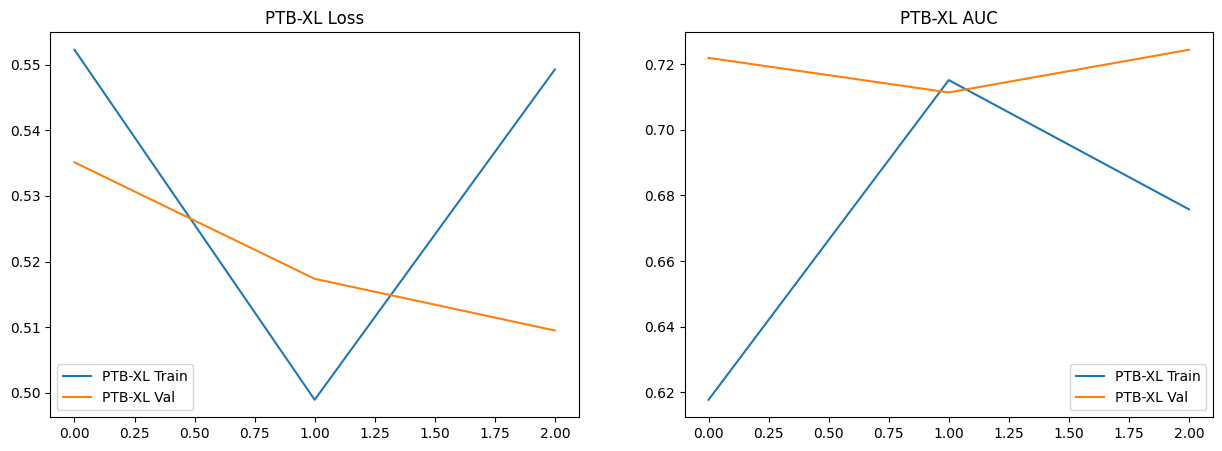

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.plot(history['train_loss'], label='PTB-XL Train'); ax1.plot(history['val_loss'], label='PTB-XL Val')
ax1.set_title('PTB-XL Loss'); ax1.legend()
ax2.plot(history['train_auc'], label='PTB-XL Train'); ax2.plot(history['val_auc'], label='PTB-XL Val')
ax2.set_title('PTB-XL AUC'); ax2.legend()
plt.show()

## 10. Export Model to ONNX for On-Device Deployment

In [ ]:
import torch.onnx

# Move model to CPU for export
model_cpu = model.to("cpu")
model_cpu.eval()

# Static input shape: batch=1, channels=1, timesteps=1000
dummy_input = torch.randn(1, 1, 1000)

onnx_path = "resnet18_ecg.onnx"
torch.onnx.export(
    model_cpu,
    dummy_input,
    onnx_path,
    input_names=["ecg_lead"],
    output_names=["mi_logit"],
    opset_version=13
)

# Convert to inline weights (PyTorch may export with external .data file)
import onnx
from onnx.external_data_helper import convert_model_from_external_data

onnx_model = onnx.load(onnx_path, load_external_data=True)
convert_model_from_external_data(onnx_model)
onnx.save(onnx_model, onnx_path)

# Clean up external data file if it exists
data_file = onnx_path + ".data"
if os.path.exists(data_file):
    os.remove(data_file)

size_mb = os.path.getsize(onnx_path) / (1024 * 1024)
print(f"ONNX model exported to: {onnx_path}")
print(f"Model size: {size_mb:.2f} MB")

# Log export to DuckDB
db.execute(
    "INSERT INTO model_exports VALUES (?, ?, ?, ?, ?, ?)",
    [RUN_ID, datetime.now(), 'onnx', onnx_path, size_mb, 'finetuned']
)


## 11. Experiment History (DuckDB)


In [13]:
# Query all logged results for this session
print("=== Training Runs ===")
print(db.execute("SELECT stage, dataset, epoch, train_loss, train_auc, val_loss, val_auc FROM runs WHERE run_id = ? ORDER BY timestamp", [RUN_ID]).df().to_string(index=False))

print("\n=== Model Exports ===")
print(db.execute("SELECT format, path, size_mb, source_stage FROM model_exports WHERE run_id = ? ORDER BY timestamp", [RUN_ID]).df().to_string(index=False))

print("\n=== All Historical Runs ===")
print(db.execute("SELECT run_id, stage, dataset, val_auc FROM runs ORDER BY timestamp").df().to_string(index=False))

db.close()


=== Training Runs ===
    stage  dataset  epoch  train_loss  train_auc  val_loss  val_auc
 pretrain   ptb-xl      1    0.552258   0.617649  0.535116 0.721973
 pretrain   ptb-xl      2    0.498954   0.715204  0.517377 0.711427
 pretrain   ptb-xl      3    0.549255   0.675759  0.509506 0.724447
zero-shot shaoxing      0         NaN        NaN  0.214193 0.781526
 finetune shaoxing      1    0.055647   0.531375       NaN 0.733936
 finetune shaoxing      2    0.016518   0.646136       NaN 0.714859

=== Model Exports ===
format              path  size_mb source_stage
  onnx resnet18_ecg.onnx 0.092173    finetuned

=== All Historical Runs ===
         run_id     stage  dataset  val_auc
20260402_173412  pretrain   ptb-xl 0.721973
20260402_173412  pretrain   ptb-xl 0.711427
20260402_173412  pretrain   ptb-xl 0.724447
20260402_173412 zero-shot shaoxing 0.781526
20260402_173412  finetune shaoxing 0.733936
20260402_173412  finetune shaoxing 0.714859
